<a href="https://colab.research.google.com/github/eiyu18/pcvk/blob/main/Weekl10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**D1. Praktikum Deteksi Obyek Dasar**

In [1]:
import cv2 as cv
import numpy as np
from matplotlib import pyplot as plt

In [39]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


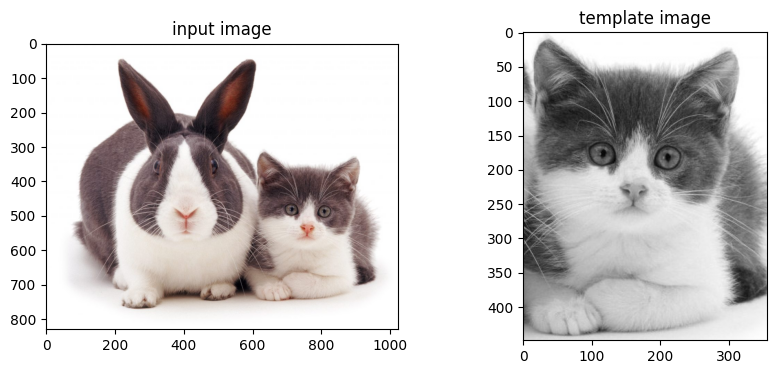

In [3]:
img_bgr = cv.imread('/content/drive/MyDrive/pcvk/Gambar/cats_and_bunnies.jpg')
tmpl = cv.imread('/content/drive/MyDrive/pcvk/Gambar/cat2_templatejpg.jpg', cv.IMREAD_GRAYSCALE)

img = cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)
img_gray = cv.cvtColor(img, cv.COLOR_RGB2GRAY)
h, w = tmpl.shape

plt.figure(figsize=(10, 4))
plt.subplot(121)
plt.imshow(img)
plt.title('input image')
plt.subplot(122)
plt.imshow(tmpl, cmap='gray')
plt.title('template image')
plt.show()

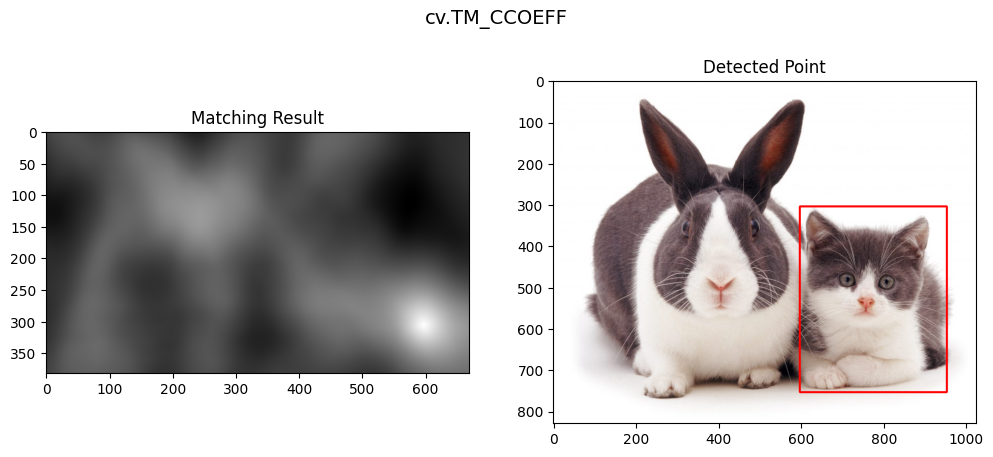

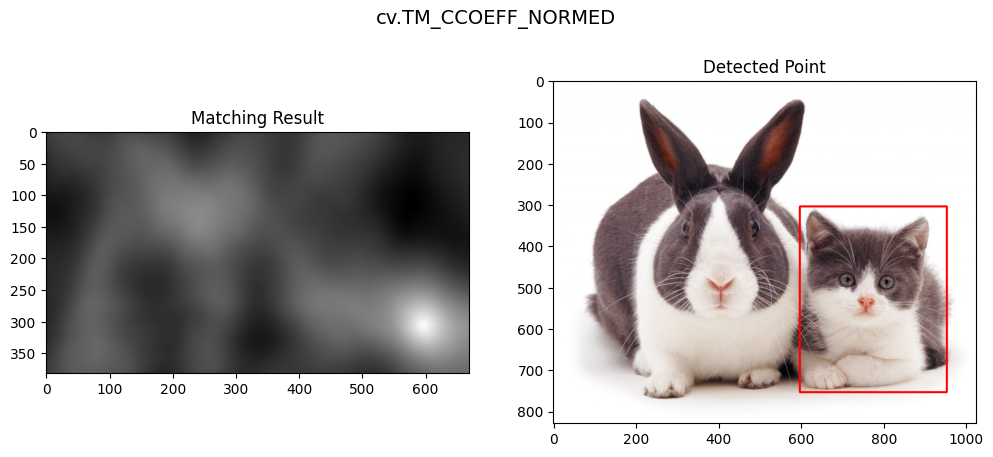

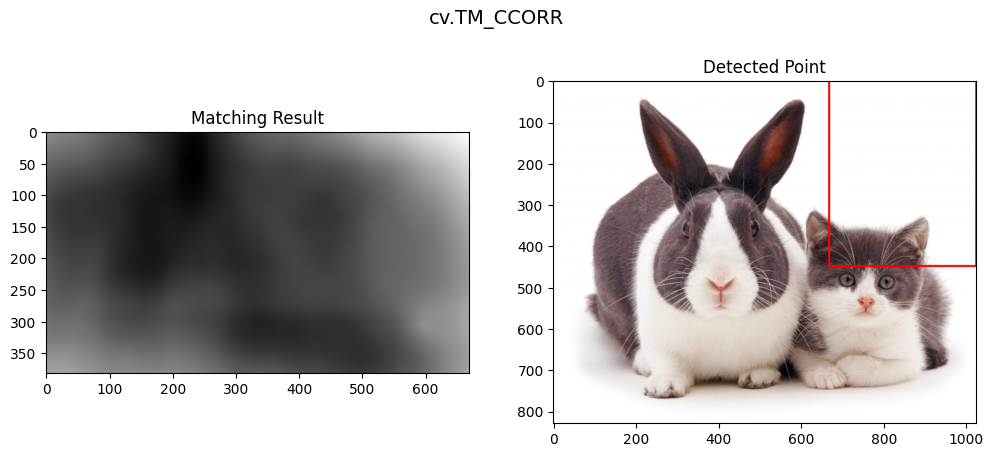

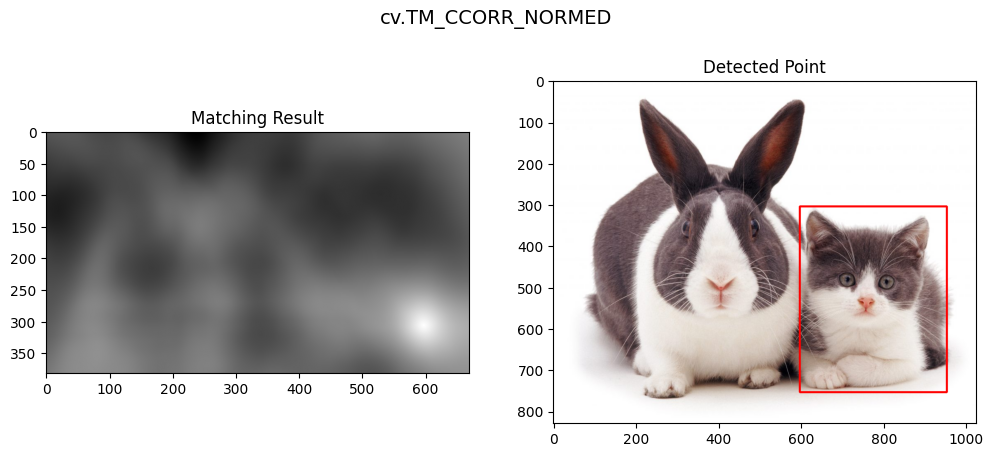

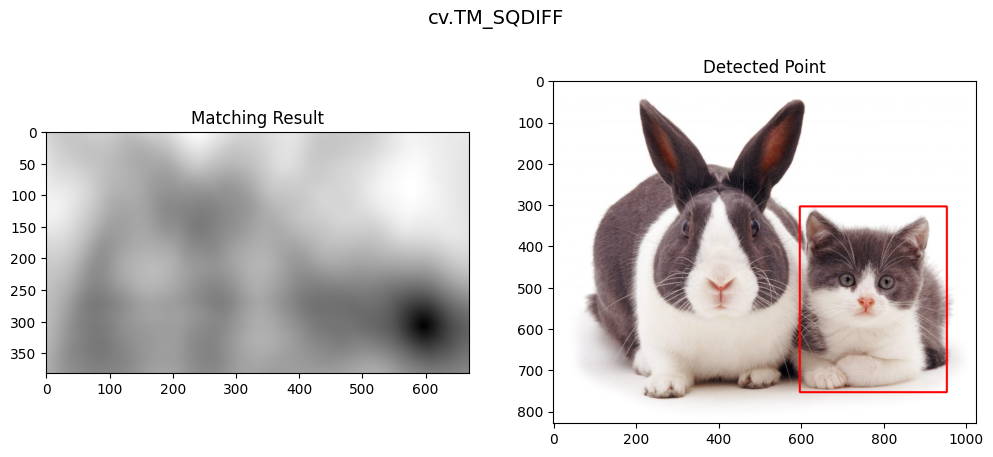

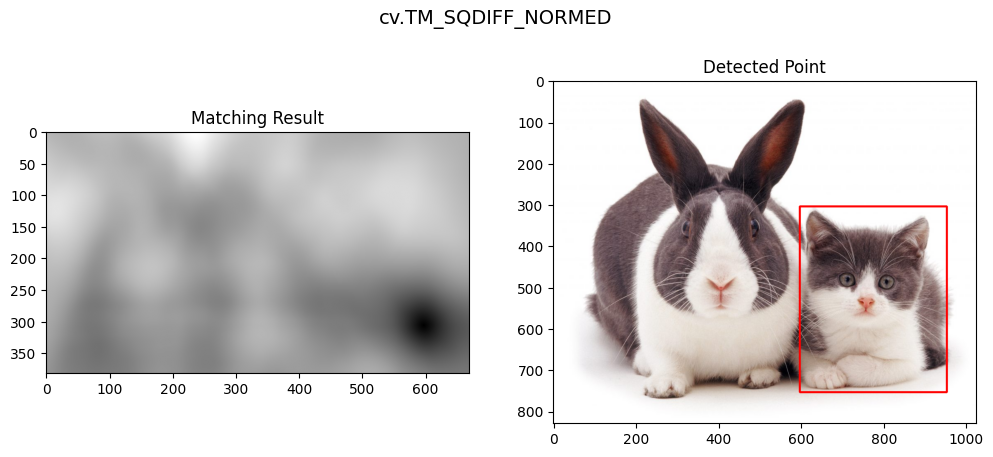

In [4]:
methods = ['cv.TM_CCOEFF', 'cv.TM_CCOEFF_NORMED', 'cv.TM_CCORR',
           'cv.TM_CCORR_NORMED', 'cv.TM_SQDIFF', 'cv.TM_SQDIFF_NORMED']

for meth in methods:
    method = getattr(cv, meth.split('.')[1])
    res = cv.matchTemplate(img_gray, tmpl, method)
    min_val, max_val, min_loc, max_loc = cv.minMaxLoc(res)

    if method in (cv.TM_SQDIFF, cv.TM_SQDIFF_NORMED):
        top_left = min_loc
    else:
        top_left = max_loc
    bottom_right = (top_left[0] + w, top_left[1] + h)

    detected = img.copy()
    cv.rectangle(detected, top_left, bottom_right, (255, 0, 0), 4)

    plt.figure(figsize=(12, 5))
    plt.suptitle(meth, fontsize=14)
    plt.subplot(121)
    plt.imshow(res, cmap='gray')
    plt.title('Matching Result')
    plt.subplot(122)
    plt.imshow(detected)
    plt.title('Detected Point')
    plt.show()

In [5]:
from matplotlib import pyplot as plt
from matplotlib.patches import Rectangle
from numpy.lib.stride_tricks import sliding_window_view

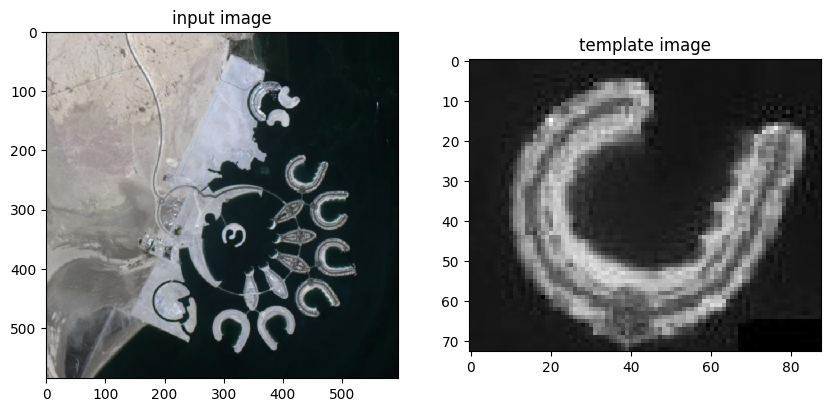

In [6]:
def to_gray(a):
    if a.ndim == 3:
        a = a[..., :3] @ np.array([0.299, 0.587, 0.114])
    return a.astype(np.float32)

src_rgb = plt.imread('/content/drive/MyDrive/pcvk/Gambar/bahrain.jpg')
tpl_rgb = plt.imread('/content/drive/MyDrive/pcvk/Gambar/bahrain-template.jpg')
src = to_gray(src_rgb)
tpl = to_gray(tpl_rgb)
th, tw = tpl.shape

plt.figure(figsize=(10, 5))
plt.subplot(121)
plt.imshow(src_rgb)
plt.title('input image')
plt.subplot(122)
plt.imshow(tpl, cmap='gray')
plt.title('template image')
plt.show()

In [7]:
def match_template(image, templ):
    t = templ - templ.mean()
    t_norm = np.sqrt((t ** 2).sum())
    th, tw = t.shape
    view = sliding_window_view(image, (th, tw))
    R = np.zeros(view.shape[:2], np.float32)
    for y in range(view.shape[0]):
        win = view[y]
        win = win - win.mean(axis=(1, 2), keepdims=True)
        num = (win * t).sum(axis=(1, 2))
        den = np.sqrt((win ** 2).sum(axis=(1, 2))) * t_norm
        R[y] = num / (den + 1e-8)
    return R

R = match_template(src, tpl)
print(R.shape, R.min(), R.max())

(514, 509) -0.4510207 0.96423805


objek terdeteksi: 6
skor: [0.964 0.576 0.52  0.499 0.475 0.471]


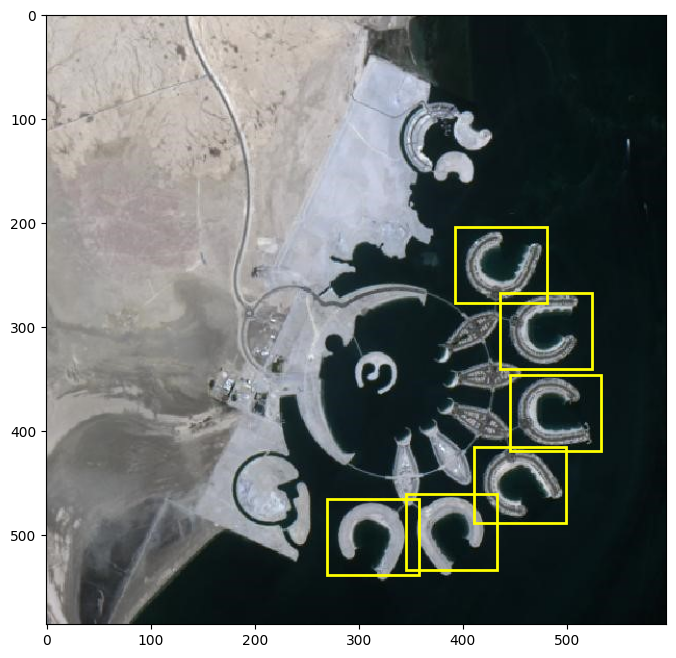

In [8]:
N_OBJECTS = 6
MIN_SCORE = 0.3
MIN_STD = 0.5 * tpl.std()

order = np.argsort(-R, axis=None)

picked = []
scores = []
for idx in order:
    y, x = np.unravel_index(idx, R.shape)
    if len(picked) >= N_OBJECTS or R[y, x] < MIN_SCORE:
        break
    if src[y:y + th, x:x + tw].std() < MIN_STD:
        continue
    if all(abs(x - px) > tw // 2 or abs(y - py) > th // 2 for px, py in picked):
        picked.append((x, y))
        scores.append(R[y, x])

print('objek terdeteksi:', len(picked))
print('skor:', np.round(scores, 3))

fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(src_rgb)
for x, y in picked:
    ax.add_patch(Rectangle((x, y), tw, th, edgecolor='yellow', facecolor='none', linewidth=2))
plt.show()

In [9]:
car = cv.cvtColor(cv.imread('/content/drive/MyDrive/pcvk/Gambar/car-park.jpg'), cv.COLOR_BGR2RGB)
gray = cv.cvtColor(car, cv.COLOR_RGB2GRAY)
blur = cv.GaussianBlur(gray, (5, 5), 0)

def show_pair(result):
    plt.figure(figsize=(16, 6))
    plt.subplot(121)
    plt.imshow(car)
    plt.subplot(122)
    plt.imshow(result, cmap='gray')
    plt.show()

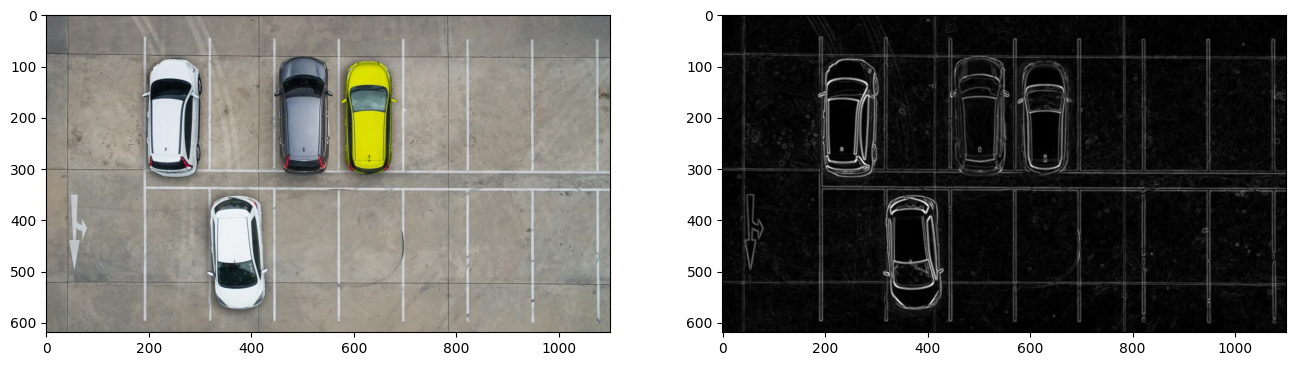

In [10]:
sobel_x = cv.Sobel(blur, cv.CV_64F, 1, 0, ksize=3)
sobel_y = cv.Sobel(blur, cv.CV_64F, 0, 1, ksize=3)
sobel = cv.addWeighted(cv.convertScaleAbs(sobel_x), 0.5,
                       cv.convertScaleAbs(sobel_y), 0.5, 0)

show_pair(sobel)

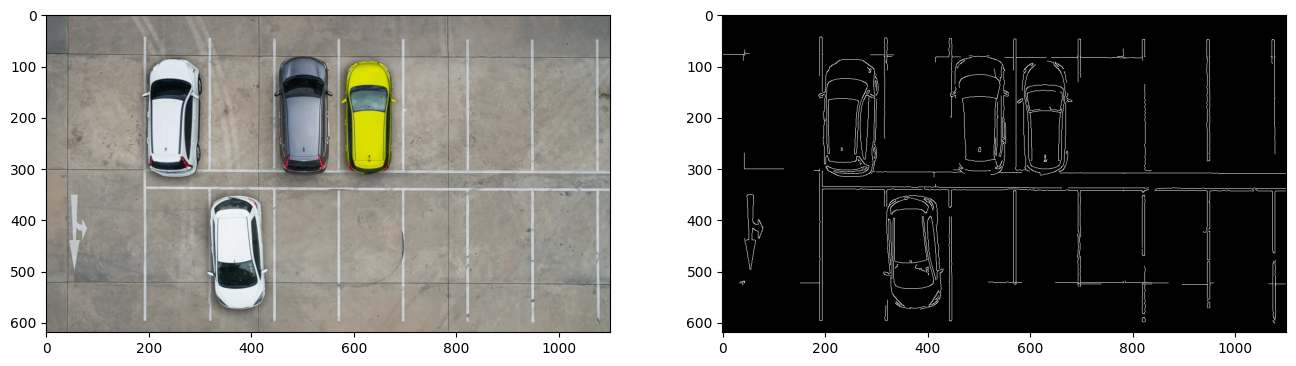

In [11]:
canny = cv.Canny(blur, 100, 200)

show_pair(canny)

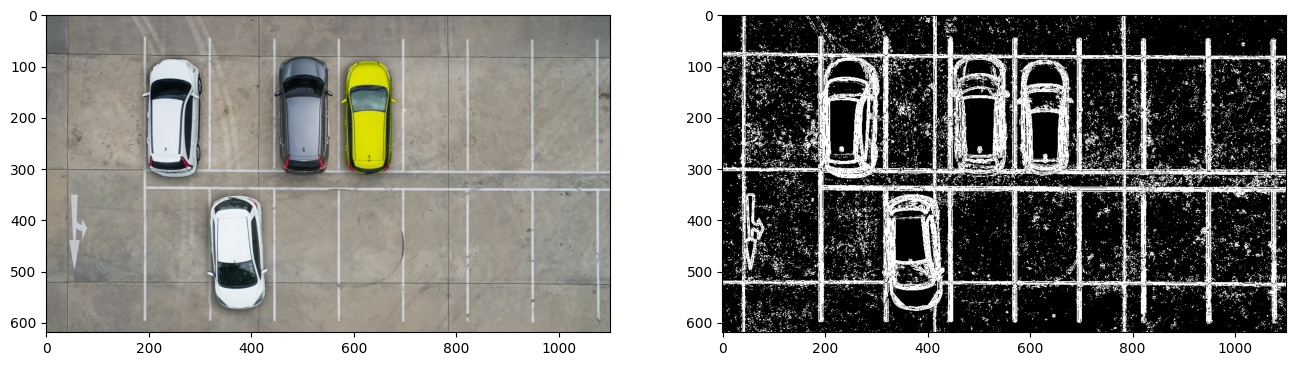

In [12]:
lap = cv.Laplacian(blur, cv.CV_64F, ksize=3)
lap = cv.convertScaleAbs(lap)
_, lap = cv.threshold(lap, 10, 255, cv.THRESH_BINARY)

show_pair(lap)

In [13]:
board = cv.cvtColor(cv.imread('/content/drive/MyDrive/pcvk/Gambar/chess-board.jpg'), cv.COLOR_BGR2RGB)
gray = cv.cvtColor(board, cv.COLOR_RGB2GRAY)

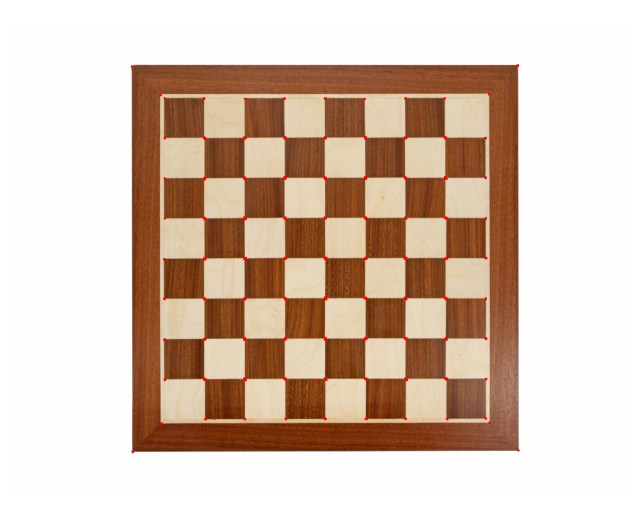

In [14]:
harris_img = board.copy()

dst = cv.cornerHarris(np.float32(gray), 2, 3, 0.04)
dst = cv.dilate(dst, None)

harris_img[dst > 0.01 * dst.max()] = [255, 0, 0]

plt.figure(figsize=(8, 8))
plt.imshow(harris_img)
plt.axis('off')
plt.show()

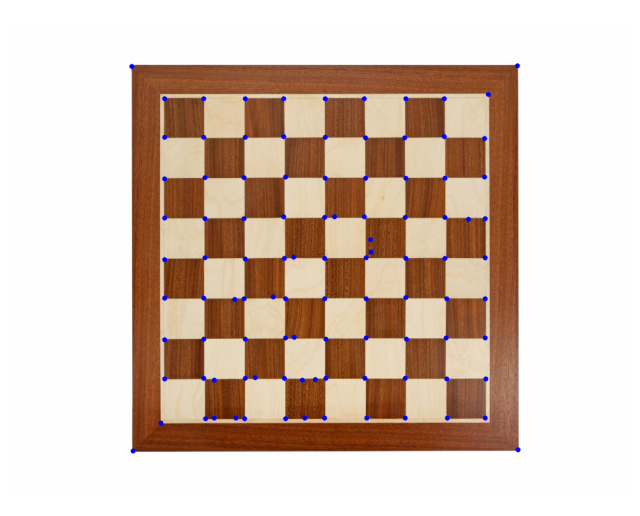

In [15]:
shi_img = board.copy()

corners = cv.goodFeaturesToTrack(gray, 100, 0.01, 10)
corners = np.intp(corners)

for c in corners:
    x, y = c.ravel()
    cv.circle(shi_img, (x, y), 4, (0, 0, 255), -1)

plt.figure(figsize=(8, 8))
plt.imshow(shi_img)
plt.axis('off')
plt.show()

In [42]:
sudoku = cv.cvtColor(cv.imread('/content/drive/MyDrive/pcvk/Gambar/sudoku.jpg'), cv.COLOR_BGR2RGB)
gray = cv.cvtColor(sudoku, cv.COLOR_RGB2GRAY)

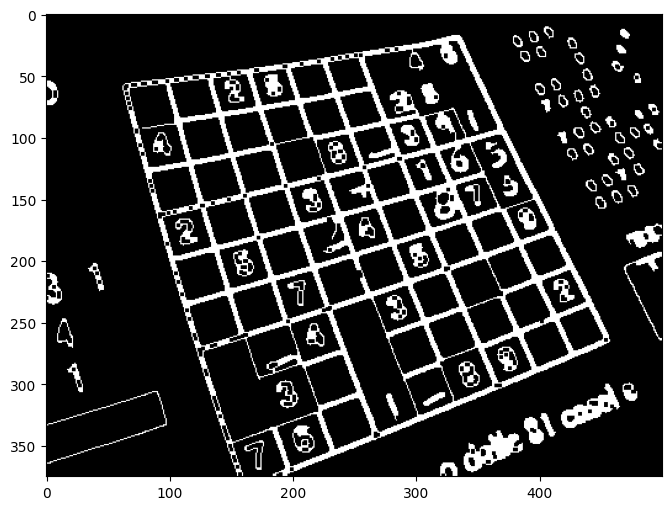

In [44]:
edges = cv.Canny(cv.GaussianBlur(gray, (5, 5), 0), 50, 150)

kernel = np.ones((3, 3), np.uint8)
edges = cv.dilate(edges, kernel, iterations=1)
edges = cv.erode(edges, kernel, iterations=1)

plt.figure(figsize=(8, 6))
plt.imshow(edges, cmap='gray')
plt.show()

In [45]:
HOUGH_THRESHOLD = 120

lines = cv.HoughLines(edges, 1, np.pi / 180, HOUGH_THRESHOLD)
print('jumlah garis:', 0 if lines is None else len(lines))

jumlah garis: 1097


In [50]:
lines = cv.HoughLines(edges, 1, np.pi / 180, 60)

def circ_diff(a, b):
    d = abs(a - b) % (2 * np.pi)
    return min(d, 2 * np.pi - d)

picked = []
for rho, theta in lines[:, 0]:
    if rho < 0:
        rho, theta = -rho, theta + np.pi
    if all(abs(rho - r) > 25 or circ_diff(theta, t) > np.pi / 24 for r, t in picked):
        picked.append((rho, theta))
    if len(picked) >= 80:
        break

print('garis Hough:', len(lines), '| setelah dibersihkan:', len(picked))

garis Hough: 6903 | setelah dibersihkan: 80


In [51]:
MAX_PER_GROUP = 10
FIRST_PASS = np.radians(25)
SECOND_PASS = np.radians(15)
MIN_GAP = 30

H, W = gray.shape

def signed(a, ref):
    return (a - ref + np.pi / 2) % np.pi - np.pi / 2

def mid_pos(rho, theta):
    if abs(np.cos(theta)) > abs(np.sin(theta)):
        return (rho - (H / 2) * np.sin(theta)) / np.cos(theta)
    return (rho - (W / 2) * np.cos(theta)) / np.sin(theta)

def build_group(ref):
    members = [(r, t) for r, t in picked if abs(signed(t, ref)) <= FIRST_PASS]
    ref = ref + np.median([signed(t, ref) for _, t in members])
    members = [(r, t) for r, t in picked if abs(signed(t, ref)) <= SECOND_PASS]
    kept = []
    for r, t in members:
        p = mid_pos(r, t)
        if all(abs(p - q) >= MIN_GAP for _, _, q in kept):
            kept.append((r, t, p))
    return [(r, t) for r, t, _ in kept][:MAX_PER_GROUP]

dir_a = picked[0][1]
dir_b = None
for rho, theta in picked:
    if abs(signed(theta, dir_a)) > np.radians(40):
        dir_b = theta
        break

group_a = build_group(dir_a)
group_b = build_group(dir_b) if dir_b is not None else []

final = group_a + group_b
print('arah 1:', len(group_a), '| arah 2:', len(group_b))

arah 1: 10 | arah 2: 10


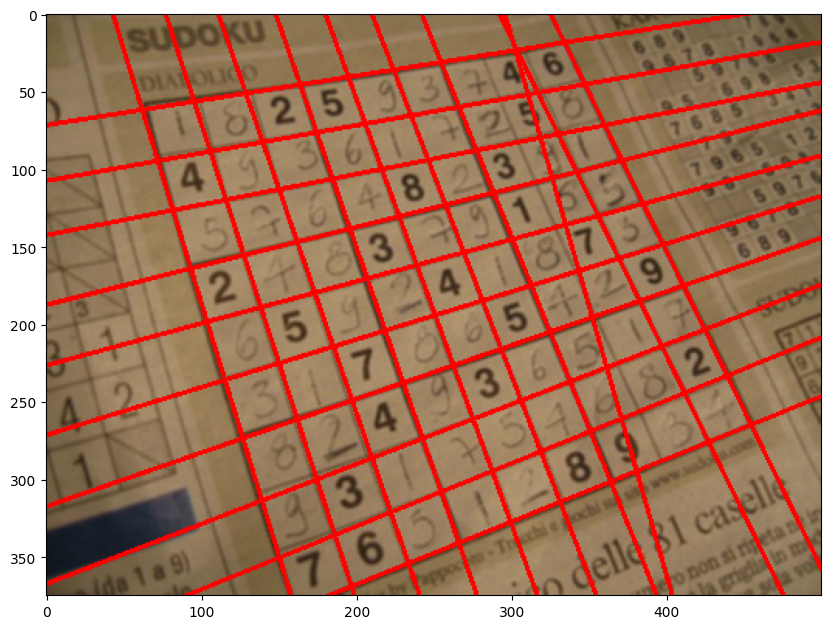

In [52]:
out = sudoku.copy()

for rho, theta in final:
    a, b = np.cos(theta), np.sin(theta)
    x0, y0 = a * rho, b * rho
    p1 = (int(x0 - 2000 * b), int(y0 + 2000 * a))
    p2 = (int(x0 + 2000 * b), int(y0 - 2000 * a))
    cv.line(out, p1, p2, (255, 0, 0), 2)

plt.figure(figsize=(10, 8))
plt.imshow(out)
plt.show()

In [28]:
laptop = cv.cvtColor(cv.imread('/content/drive/MyDrive/pcvk/Gambar/laptop.jpg'), cv.COLOR_BGR2RGB)
gray = cv.cvtColor(laptop, cv.COLOR_RGB2GRAY)

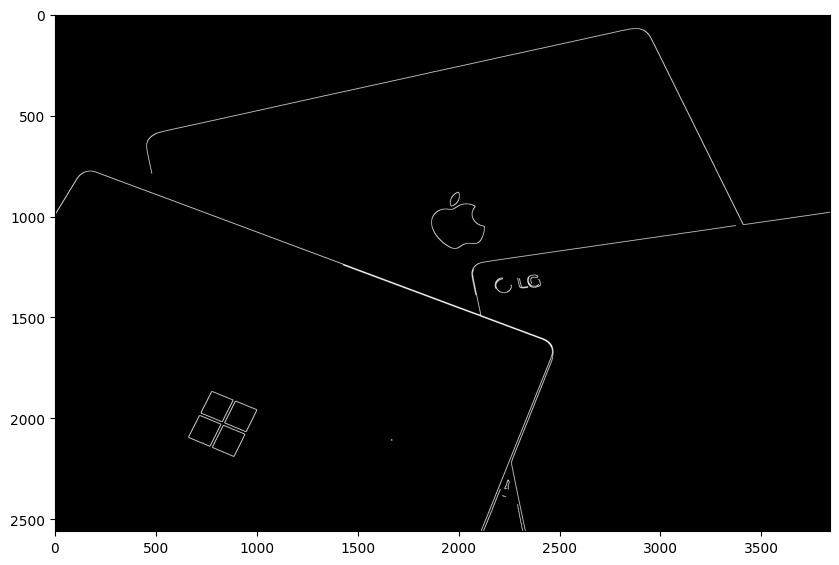

In [29]:
blur = cv.GaussianBlur(gray, (7, 7), 0)
binary = cv.Canny(blur, 50, 150)
binary = cv.dilate(binary, np.ones((3, 3), np.uint8), iterations=1)

plt.figure(figsize=(10, 7))
plt.imshow(binary, cmap='gray')
plt.show()

jumlah kontur: 109


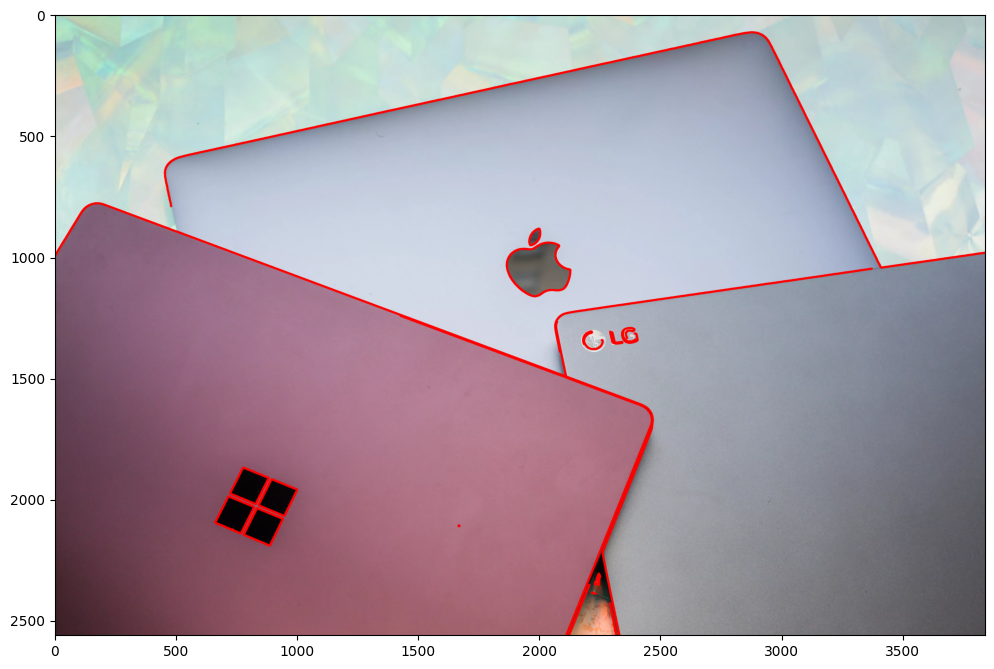

In [30]:
contours, hierarchy = cv.findContours(binary, cv.RETR_TREE, cv.CHAIN_APPROX_SIMPLE)
print('jumlah kontur:', len(contours))

out = laptop.copy()
cv.drawContours(out, contours, -1, (255, 0, 0), 5)

plt.figure(figsize=(12, 9))
plt.imshow(out)
plt.show()

**D2. Praktikum Feature Matching dan Face Detection**